# Shop Size Classes

<div dir="rtl">

در مغازه‌ها چیزی که اهمیت دارد بیشتر دسترسی و ویترین است تا خود متراژ. اگر این حرف درست باشد، مغازه‌های کوچک‌تر باید قیمت هر متر بیشتری داشته باشند. متراژ مغازه را به چهار دسته تبدیل می‌کنیم و این فرض را برای فروش و اجاره بررسی می‌کنیم.

</div>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kruskal

df = pd.read_parquet('divar_clean.parquet', columns=['cat3_slug', 'city_slug', 'building_size', 'price_per_m2'])
shops = df[df['cat3_slug'].isin(['shop-sell', 'shop-rent'])].copy()

shops['relative_price'] = shops['price_per_m2'] / shops.groupby(['city_slug', 'cat3_slug'])['price_per_m2'].transform('median')
shops['size_class'] = pd.cut(shops['building_size'], [0, 20, 50, 100, float('inf')],
                             right=False, labels=['<20', '20-50', '50-100', '100+'])

<div dir="rtl">

`relative_price` یعنی قیمت هر متر یک مغازه تقسیم بر میانه‌ی مغازه‌های همان شهر و همان نوع معامله. عدد ۱ یعنی قیمت معمول آن شهر.

</div>

In [2]:
table = shops.pivot_table(index='size_class', columns='cat3_slug', values='relative_price',
                          aggfunc=['count', 'median'], observed=True)
table.round(2)

count              median          
cat3_slug  shop-rent shop-sell shop-rent shop-sell
size_class                                        
<20             8056      4552      1.39      1.19
20-50          17185      7232      1.10      1.02
50-100          8415      2766      0.83      0.86
100+            8882      2339      0.66      0.70

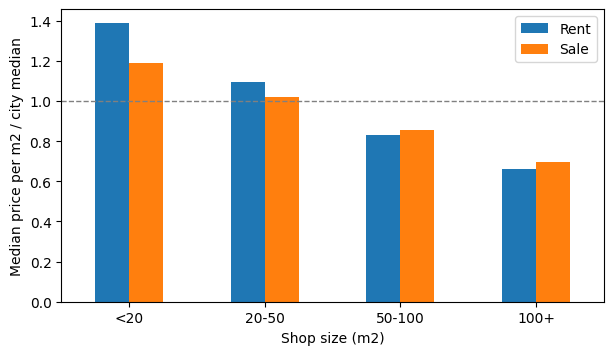

In [3]:
ax = table['median'].plot(kind='bar', rot=0, figsize=(7, 3.8))
ax.legend(['Rent', 'Sale'])
ax.axhline(1, color='grey', ls='--', lw=1)
ax.set_xlabel('Shop size (m2)')
ax.set_ylabel('Median price per m2 / city median')
plt.show()

<div dir="rtl">

**فرض صفر:** قیمت نسبی هر متر در چهار دسته‌ی متراژ یکسان است. آزمون Kruskal-Wallis، و اندازه‌ی اثر با ε².

</div>

In [4]:
def kruskal_eps(part):
    groups = [g.dropna() for _, g in part.groupby('size_class', observed=True)['relative_price']]
    h, p = kruskal(*groups)
    n = sum(len(g) for g in groups)
    return p, (h - len(groups) + 1) / (n - len(groups))

for cat in ['shop-sell', 'shop-rent']:
    p, eps2 = kruskal_eps(shops[shops['cat3_slug'] == cat])
    print(f'{cat}: p-value = {p:.2g}, epsilon squared = {eps2:.3f}')

shop-sell: p-value = 1.9e-189, epsilon squared = 0.052
shop-rent: p-value = 0, epsilon squared = 0.100


<div dir="rtl">

فرض صفر در هر دو حالت رد می‌شود و جهت هم همان چیزی است که انتظار داشتیم: هرچه مغازه کوچک‌تر باشد، هر مترش گران‌تر است. اثر در اجاره متوسط است و در فروش ضعیف. در اجاره، هر متر مغازه‌های زیر ۲۰ متر حدود دو برابر مغازه‌های بالای ۱۰۰ متر قیمت دارد.

این دقیقاً برعکس آپارتمان‌هاست، که در آن‌ها واحد بزرگ‌تر قیمت هر متر بیشتری داشت. پس قیمت هر متر را نمی‌شود با یک قاعده‌ی ثابت برای همه‌ی دسته‌ها تخمین زد. برای مستأجری که مغازه می‌خواهد، یعنی متراژ بیشتر با قیمت هر متر کمتر به دست می‌آید. برای مالک هم یعنی تقسیم یک مغازه‌ی بزرگ به چند واحد کوچک می‌تواند درآمد بیشتری بیاورد.

</div>